## 1. Load the randomized experiment

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, norm

ALPHA = 0.05
REPS = 5000
SEED = 20261108
DATA_URL = 'https://raw.githubusercontent.com/AdityaDabrase/ab-testing-email-marketing/main/data/raw/hillstrom.csv'

if Path('hillstrom.csv').exists():
    df = pd.read_csv('hillstrom.csv')
else:
    try:
        df = pd.read_csv(DATA_URL)
    except Exception as exc:
        raise RuntimeError('Download hillstrom.csv and place it beside this script.') from exc

mapping = {'Mens E-Mail': 'A', 'Womens E-Mail': 'B', 'No E-Mail': 'C'}
assert {'segment', 'conversion'}.issubset(df.columns)
df['arm'] = df['segment'].astype(str).str.strip().map(mapping)
assert df['arm'].notna().all(), 'Unexpected group labels.'
assert not df[['conversion', 'arm']].isna().any().any()
assert df['conversion'].isin([0, 1]).all()

summary = df.groupby('arm')['conversion'].agg(n='size', x='sum', p='mean').loc[['A', 'B', 'C']]
summary['rate_percent'] = 100 * summary['p']
summary.to_csv('observed_conversion_summary.csv')
print('Observed conversion summary:\n', summary.to_string())
p0 = float(summary.loc['C', 'p'])
actual_n = int(min(summary.loc['A', 'n'], summary.loc['C', 'n']))
print(f'Baseline (no email) conversion probability: {p0:.6f}')
print(f'Planning n based on smaller A/C arm: {actual_n}')

Observed conversion summary:
          n    x         p  rate_percent
arm                                    
A    21307  267  0.012531      1.253109
B    21387  189  0.008837      0.883714
C    21306  122  0.005726      0.572609
Baseline (no email) conversion probability: 0.005726
Planning n based on smaller A/C arm: 21306


## 2. Binomial likelihood-ratio tests with Holm adjustment

In [ ]:
# Vectorized across simulated experiments; arrays have shape (REPS,).
def binomial_loglik(x, n, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return x * np.log(p) + (n - x) * np.log1p(-p)

def pair_lrt_pvalue(x1, x2, n1, n2):
    x1 = np.asarray(x1, dtype=float)
    x2 = np.asarray(x2, dtype=float)
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    unrestricted = binomial_loglik(x1, n1, p1) + binomial_loglik(x2, n2, p2)
    restricted = binomial_loglik(x1, n1, pooled) + binomial_loglik(x2, n2, pooled)
    statistic = np.maximum(0, 2 * (unrestricted - restricted))
    return chi2.sf(statistic, df=1)

def holm_adjust(pvalues):
    """Three simultaneous tests; input shape (replicates, 3)."""
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues, axis=1)
    ranked = np.take_along_axis(pvalues, order, axis=1)
    ranked_adj = np.maximum.accumulate(ranked * [3, 2, 1], axis=1)
    result = np.empty_like(pvalues)
    np.put_along_axis(result, order, np.minimum(ranked_adj, 1), axis=1)
    return result

def simulate(n, p_a, p_b, p_c, reps, rng):
    x_a = rng.binomial(n, p_a, size=reps)
    x_b = rng.binomial(n, p_b, size=reps)
    x_c = rng.binomial(n, p_c, size=reps)
    pvals = np.column_stack([
        pair_lrt_pvalue(x_a, x_b, n, n),
        pair_lrt_pvalue(x_a, x_c, n, n),
        pair_lrt_pvalue(x_b, x_c, n, n)
    ])
    reject = holm_adjust(pvals) < ALPHA
    return reject.mean(axis=0)  # P(reject AB), P(reject AC), P(reject BC)

# Sanity checks (both exact-null and pronounced alternative)
assert np.isclose(pair_lrt_pvalue([1], [1], 100, 100)[0], 1)
assert np.all(holm_adjust(np.array([[.001, .03, .2]])) <= 1)

## 3. Monte Carlo power curves and heatmap


Power results (head):
     n  delta  power_AB  power_AC  rejection_BC
 2500  0.001    0.0302    0.0314        0.0216
 5000  0.001    0.0472    0.0466        0.0202
10000  0.001    0.0770    0.0716        0.0198
20000  0.001    0.1410    0.1424        0.0218
30000  0.001    0.2142    0.2112        0.0208


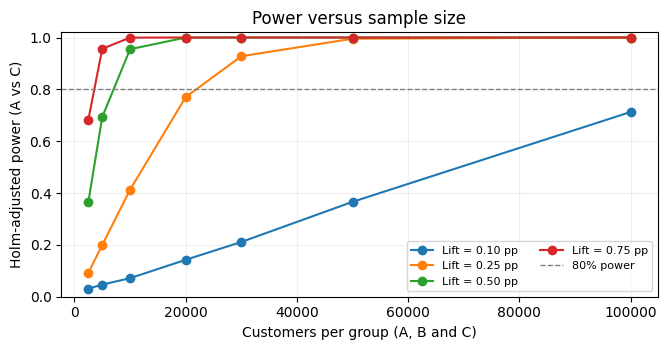

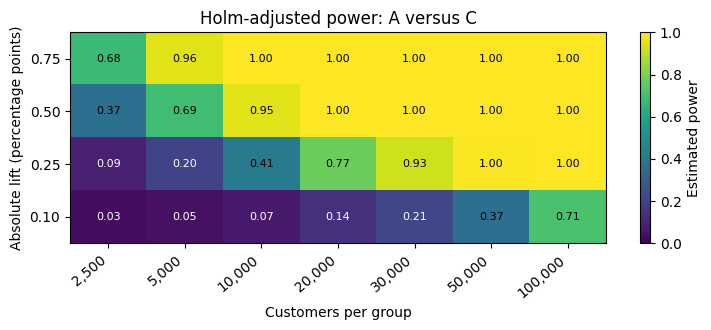

In [ ]:
# Intervention scenario: A's effect = delta, B's effect = 0, C = baseline.
# Accordingly AB and AC are false nulls, BC is true.
rng = np.random.default_rng(SEED)
n_grid = np.array([2500, 5000, 10000, 20000, 30000, 50000, 100000])
delta_grid = np.array([0.001, 0.0025, 0.005, 0.0075])
rows = []
for delta in delta_grid:
    for n in n_grid:
        assert p0 + delta < 1
        power_ab, power_ac, rejection_bc = simulate(n, p0 + delta, p0, p0, REPS, rng)
        rows.append(dict(n=int(n), delta=float(delta), power_AB=power_ab,
                         power_AC=power_ac, rejection_BC=rejection_bc))
power_df = pd.DataFrame(rows)
power_df.to_csv('power_results.csv', index=False)
print('\nPower results (head):\n', power_df.head().to_string(index=False))

fig, ax = plt.subplots(figsize=(6.8, 3.6))
for delta in delta_grid:
    sub = power_df[power_df['delta'] == delta]
    ax.plot(sub['n'], sub['power_AC'], 'o-', label=f'Lift = {100*delta:.2f} pp')
ax.axhline(0.8, ls='--', color='grey', lw=1, label='80% power')
ax.set(xlabel='Customers per group (A, B and C)', ylabel='Holm-adjusted power (A vs C)',
       title='Power versus sample size')
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig('power_curves.pdf', bbox_inches='tight')
fig.savefig('power_curves.png', dpi=200, bbox_inches='tight')
plt.show()

mat = power_df.pivot(index='delta', columns='n', values='power_AC').loc[delta_grid, n_grid]
fig, ax = plt.subplots(figsize=(7.6, 3.4))
im = ax.imshow(mat.values, origin='lower', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(np.arange(len(n_grid)), [f'{n:,}' for n in n_grid], rotation=40, ha='right')
ax.set_yticks(np.arange(len(delta_grid)), [f'{100*d:.2f}' for d in delta_grid])
ax.set(xlabel='Customers per group', ylabel='Absolute lift (percentage points)',
       title='Holm-adjusted power: A versus C')
for i in range(len(delta_grid)):
    for j in range(len(n_grid)):
        ax.text(j, i, f'{mat.values[i,j]:.2f}', ha='center', va='center',
                fontsize=8, color='white' if mat.values[i,j] < 0.35 else 'black')
fig.colorbar(im, ax=ax, label='Estimated power')
fig.tight_layout()
fig.savefig('power_heatmap.pdf', bbox_inches='tight')
fig.savefig('power_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Approximate sample size and simulation-based MDE

In [ ]:
def sample_size_two_proportions(p_c, delta, target_power, alpha_pair):
    p_a = p_c + delta
    q = (p_a + p_c) / 2
    za = norm.ppf(1 - alpha_pair / 2)
    zb = norm.ppf(target_power)
    numer = (za * np.sqrt(2*q*(1-q)) +
             zb * np.sqrt(p_a*(1-p_a) + p_c*(1-p_c))) ** 2
    return int(np.ceil(numer / delta**2))

sizes = []
for delta in [0.0025, 0.005, 0.0075]:
    n80 = sample_size_two_proportions(p0, delta, 0.80, ALPHA / 3)
    n90 = sample_size_two_proportions(p0, delta, 0.90, ALPHA / 3)
    sizes.append(dict(delta_pp=100*delta, n_per_group_80=n80,
                      n_per_group_90=n90, total_3arms_80=3*n80))
size_df = pd.DataFrame(sizes)
size_df.to_csv('sample_size_results.csv', index=False)
print('\nConservative pairwise sample sizes (Bonferroni alpha=0.05/3):\n',
      size_df.to_string(index=False))

# Estimate MDE on a specified effect-size grid for the actual A/C arm size
# and a proposed future study, using the full Holm-adjusted procedure.
rng_mde = np.random.default_rng(SEED + 1)
mde_delta_grid = np.arange(0.00025, 0.01251, 0.00025)
mde_rows = []
for n in [actual_n, 50000]:
    curve = []
    for delta in mde_delta_grid:
        _, power_ac, _ = simulate(n, p0+delta, p0, p0, REPS, rng_mde)
        curve.append(power_ac)
    curve = np.array(curve)
    passing = np.flatnonzero(curve >= 0.80)
    mde = float(mde_delta_grid[passing[0]]) if len(passing) else np.nan
    mde_rows.append(dict(n_per_group=n, mde_pp=100*mde))
mde_df = pd.DataFrame(mde_rows)
mde_df.to_csv('mde_results.csv', index=False)
print('\nApproximate simulation MDE (80% power, 0.025 pp grid resolution):\n',
      mde_df.to_string(index=False))


Conservative pairwise sample sizes (Bonferroni alpha=0.05/3):
  delta_pp  n_per_group_80  n_per_group_90  total_3arms_80
     0.25           23207           29946           69621
     0.50            6832            8815           20496
     0.75            3493            4507           10479

Approximate simulation MDE (80% power, 0.025 pp grid resolution):
  n_per_group  mde_pp
       21306   0.275
       50000   0.175


## 5. Business effect sizes and hypothetical cost scenarios

In [ ]:
# These are point-estimate exercises, NOT actual profit claims.
rows = []
for arm in ['A', 'B']:
    diff = float(summary.loc[arm, 'p'] - p0)
    rows.append(dict(arm=arm, observed_lift_pp=100*diff,
                     extra_buyers_per_1000=1000*diff,
                     extra_buyers_per_100k=100000*diff))
business_df = pd.DataFrame(rows)
business_df.to_csv('business_lift.csv', index=False)
print('\nEstimated incremental purchasers (not profit):\n',
      business_df.to_string(index=False))

cost_per_email = 0.02  # hypothetical USD; NOT given in Hillstrom
sensitivity = []
for margin in [10, 20, 40]:  # hypothetical contribution margin, USD/additional purchaser
    for arm in ['A', 'B']:
        delta_hat = float(summary.loc[arm, 'p'] - p0)
        sensitivity.append(dict(arm=arm, margin_USD=margin,
                                cost_per_email_USD=cost_per_email,
                                breakeven_lift_pp=100*cost_per_email/margin,
                                incremental_profit_per_1000_USD=
                                1000*(delta_hat*margin-cost_per_email)))
sensitivity_df = pd.DataFrame(sensitivity)
sensitivity_df.to_csv('business_sensitivity.csv', index=False)
print('\nIllustrative economic sensitivity (assumed costs/margins):\n',
      sensitivity_df.to_string(index=False))

print('\nFiles created: power_curves.pdf/.png, power_heatmap.pdf/.png,')
print('observed_conversion_summary.csv, power_results.csv, sample_size_results.csv,')
print('mde_results.csv, business_lift.csv, business_sensitivity.csv.')


Estimated incremental purchasers (not profit):
 arm  observed_lift_pp  extra_buyers_per_1000  extra_buyers_per_100k
  A          0.680501               6.805007             680.500652
  B          0.311106               3.111058             311.105751

Illustrative economic sensitivity (assumed costs/margins):
 arm  margin_USD  cost_per_email_USD  breakeven_lift_pp  incremental_profit_per_1000_USD
  A          10                0.02               0.20                        48.050065
  B          10                0.02               0.20                        11.110575
  A          20                0.02               0.10                       116.100130
  B          20                0.02               0.10                        42.221150
  A          40                0.02               0.05                       252.200261
  B          40                0.02               0.05                       104.442300

Files created: power_curves.pdf/.png, power_heatmap.pdf/.png,
observe